<a href="https://colab.research.google.com/github/w4bo/AA2627-unibo-dcai/blob/main/slides/lab-03-feature.ipynb" target="_parent"><img src="img/colab-badge.svg" alt="Open In Colab"/></a>

---
title: "From Domain Features to Automated Feature Selection"
---

# Feature engineering versus feature selection

**Feature engineering** introduces hypotheses about the problem by creating candidate inputs for a model.

- It turns domain knowledge into measurable variables: ratios, differences, nonlinear transformations, and aggregations.

**Feature selection** controls complexity by choosing a subset of candidate inputs. 

- It tries to keep signal while removing redundancy, noise, and sources of overfitting.

A feature is useful when:

- It carries **signal** about the target.
- It is not just a duplicate of another feature.
- It is stable across samples, folds, and time periods.
- It is available at the moment the model is used.

In [ ]:
#| echo: false

# Import the tools needed for reproducible feature engineering, selection, and evaluation.
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import RFE, SelectKBest, SequentialFeatureSelector, mutual_info_classif
from sklearn.metrics import balanced_accuracy_score, f1_score, make_scorer
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [ ]:
#| echo: false
rng = np.random.default_rng(42)
n = 5_000

airports = np.array(["ATL", "BOS", "JFK", "LAX", "SFO"])
carriers = np.array(["AA", "DL", "UA", "WN", "B6"])

# Schedule and route
scheduled_departure = (pd.Timestamp("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D") + pd.to_timedelta(rng.integers(0, 24, n), unit="h") + pd.to_timedelta(rng.choice([0, 10, 15, 20, 30, 40, 45, 50], n), unit="m"))
origin = rng.choice(airports, n)
destination = rng.choice(airports, n)

while (origin == destination).any():
    mask = origin == destination
    destination[mask] = rng.choice(airports, mask.sum())

# Synthetic distance is sufficient for this feature-engineering exercise.
distance_km = rng.integers(300, 4_500, n)
scheduled_duration_min = np.round(35 + distance_km / 12.5).astype(int)
scheduled_arrival = scheduled_departure + pd.to_timedelta(scheduled_duration_min, unit="m")

# Correlated duplicate wind forecasts
true_wind = np.clip(rng.gamma(2.3, 5, n), 0, 45)
weather_wind1 = np.clip(true_wind + rng.normal(0, 1.3, n), 0, None)
weather_wind2 = np.clip(true_wind + rng.normal(0, 1.7, n), 0, None)

# Correlated duplicate precipitation forecasts
true_rain = np.where(rng.random(n) < 0.40, rng.gamma(1.8, 5.5, n), 0,)
weather_rain1 = np.clip(true_rain + rng.normal(0, 0.7, n), 0, None)
weather_rain2 = np.clip(true_rain + rng.normal(0, 1, n), 0, None)

df = pd.DataFrame(
    {
        "scheduled_departure": scheduled_departure,
        "scheduled_arrival": scheduled_arrival,
        "carrier": rng.choice(carriers, n),
        "origin": origin,
        "destination": destination,
        "distance_km": distance_km,
        "weather_wind1": weather_wind1.round(2),
        "weather_wind2": weather_wind2.round(2),
        "weather_rain1": weather_rain1.round(2),
        "weather_rain2": weather_rain2.round(2),
        "noise_1": rng.normal(0, 1, n).round(4),
        "noise_2": rng.uniform(-1, 1, n).round(4),
        "noise_3": rng.integers(0, 100, n),
    }
)

# Engineered features
holidays = pd.to_datetime(["2025-01-01","2025-01-20","2025-02-17","2025-05-26","2025-07-04","2025-09-01","2025-11-27","2025-12-24","2025-12-25","2025-12-31",])

df = df.assign(
    route=df["origin"] + "-" + df["destination"],
    scheduled_duration_min=scheduled_duration_min,
    departure_hour=df["scheduled_departure"].dt.hour,
    is_holiday=(df["scheduled_departure"].dt.normalize().isin(holidays) | df["scheduled_departure"].dt.dayofweek.eq(6)).astype(int),
)

df = df.assign(
    is_late_night=((df["departure_hour"] >= 20) | (df["departure_hour"] <= 4)).astype(int),
    high_precipitation=(df["weather_rain1"] >= 12).astype(int),
)

df = df.assign(
    holiday_late_night=df["is_holiday"] * df["is_late_night"],
    airport_limited_visibility=(((df["destination"] == "SFO") | (df["origin"] == "SFO")) & (df["distance_km"] > 1500) & (rng.random(n) < 0.6)).astype(int),
)

# Delay probability: requested rules receive strong coefficients.
delay_probability = 1 / (1 + np.exp(-(-0.6 + 3.0 * df["holiday_late_night"] + 2.7 * df["high_precipitation"] + 3.2 * df["airport_limited_visibility"])))
delay_event = rng.random(n) < delay_probability

# Generate arrival-delay magnitude.
arrival_delay_min = (rng.normal(-3, 6, n) + delay_event * rng.gamma(2.2, 8, n) + df["holiday_late_night"] * rng.gamma(2.5, 9, n) + df["high_precipitation"] * rng.gamma(2.8, 10, n) + df["airport_limited_visibility"] * rng.gamma(2.5, 12, n) + np.maximum(df["weather_rain1"] - 20, 0) * 0.8).round().clip(-20, 300).astype(int)

df["departure_delay_min"] = (
    0.65 * np.maximum(arrival_delay_min, 0) + rng.normal(0, 7, n)
).round().clip(-10, 240).astype(int)

df["actual_departure"] = df["scheduled_departure"] + pd.to_timedelta(
    df["departure_delay_min"], unit="m"
)

df["actual_arrival"] = df["scheduled_arrival"] + pd.to_timedelta(
    arrival_delay_min, unit="m"
)

# Calculate the target from the timestamps.
df["arrival_delay_min"] = ((df["actual_arrival"] - df["scheduled_arrival"]).dt.total_seconds().div(60).astype(int))
df["delayed_15_min"] = (df["arrival_delay_min"] >= 15).astype(int)

# Keep the full dataframe for teaching/auditing the synthetic rules.
delay_rule_summary = df.groupby(
    ["holiday_late_night", "high_precipitation", "airport_limited_visibility"]
)["delayed_15_min"].agg(["count", "sum", "mean"]).round(3)

# The model input starts from raw, prediction-time columns plus actual timestamps for the leakage discussion.
engineered_rule_columns = [
    "route",
    "departure_hour",
    "is_holiday",
    "is_late_night",
    "high_precipitation",
    "holiday_late_night",
    "airport_limited_visibility",
]
leaky_outcome_columns = ["departure_delay_min", "arrival_delay_min", "delayed_15_min"]
X = df.drop(columns=engineered_rule_columns + leaky_outcome_columns)
y = df["delayed_15_min"].rename("arrival_delay_15min")

# df.to_csv("synthetic_flight_delays.csv", index=False)
# df.groupby(["is_holiday", "is_late_night", "high_precipitation", "airport_limited_visibility"]).agg({"delayed_15_min": ["count", "sum", "mean"]}).round(2)
# df.groupby(["airport_limited_visibility"]).agg({"delayed_15_min": ["count", "sum", "mean"]}).round(2)


# Flight delay prediction: predict whether a flight arrives at least 15 minutes late


In [ ]:
X.head(n=3)

,scheduled_departure,scheduled_arrival,carrier,origin,destination,distance_km,weather_wind1,weather_wind2,weather_rain1,weather_rain2,noise_1,noise_2,noise_3,scheduled_duration_min,actual_departure,actual_arrival
0,2025-02-02 04:15:00,2025-02-02 06:03:00,UA,ATL,SFO,918,4.76,5.09,0.56,0.00,0.4405,0.2071,83,108,2025-02-02 04:39:00,2025-02-02 06:45:00
1,2025-10-10 00:10:00,2025-10-10 03:11:00,AA,JFK,LAX,1826,26.43,26.82,0.84,0.00,1.8638,0.7937,27,181,2025-10-10 00:06:00,2025-10-10 03:10:00
2,2025-08-27 15:30:00,2025-08-27 19:18:00,B6,JFK,BOS,2409,2.80,0.83,13.91,12.32,1.1118,-0.6341,29,228,2025-08-27 16:23:00,2025-08-27 20:40:00


In [ ]:
y.value_counts(normalize=True)

arrival_delay_15min
0    0.6068
1    0.3932
Name: proportion, dtype: float64

# Data understanding

In [ ]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   scheduled_departure     5000 non-null   datetime64[us]
 1   scheduled_arrival       5000 non-null   datetime64[us]
 2   carrier                 5000 non-null   str           
 3   origin                  5000 non-null   str           
 4   destination             5000 non-null   str           
 5   distance_km             5000 non-null   int64         
 6   weather_wind1           5000 non-null   float64       
 7   weather_wind2           5000 non-null   float64       
 8   weather_rain1           5000 non-null   float64       
 9   weather_rain2           5000 non-null   float64       
 10  noise_1                 5000 non-null   float64       
 11  noise_2                 5000 non-null   float64       
 12  noise_3                 5000 non-null   int64         
 13 

# Redundant features and irrelevant noise

- The two rain forecasts can carry almost the same information. 
- A rain forecast is somewhat correlated with the target, but it is not a perfect predictor.
- An independent noise column has similar distributions in the two classes.

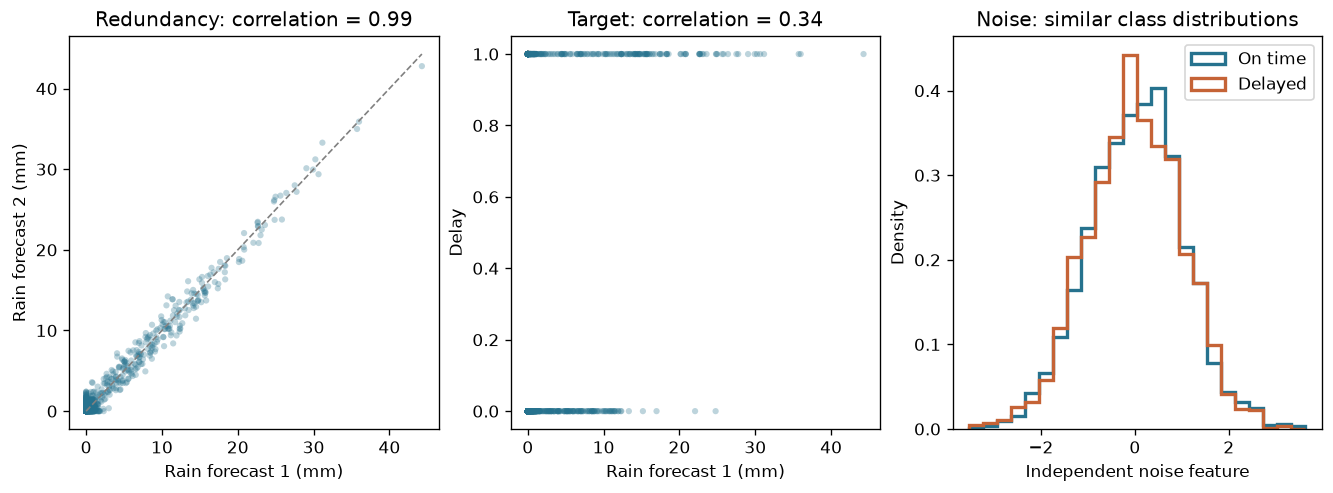

In [ ]:
#| echo: false
#| out-height: "400px"
forecast_sample = X.sample(n=min(800, len(X)), random_state=RANDOM_STATE)
y_sample = y.loc[forecast_sample.index]
fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout='constrained')
axes[0].scatter(forecast_sample['weather_rain1'], forecast_sample['weather_rain2'], s=14, alpha=0.3, color='#26728e', edgecolors='none')
forecast_limit = forecast_sample[['weather_rain1', 'weather_rain2']].to_numpy().max()
axes[0].plot([0, forecast_limit], [0, forecast_limit], '--', color='gray', linewidth=1)
axes[0].set(xlabel='Rain forecast 1 (mm)', ylabel='Rain forecast 2 (mm)', title=f'Redundancy: correlation = {X.weather_rain1.corr(X.weather_rain2):.2f}')
axes[1].scatter(forecast_sample['weather_rain1'], y_sample, s=14, alpha=0.3, color='#26728e', edgecolors='none')
axes[1].set(xlabel='Rain forecast 1 (mm)', ylabel='Delay', title=f'Target: correlation = {X.weather_rain1.corr(y_sample):.2f}')
noise_bins = np.linspace(X['noise_1'].min(), X['noise_1'].max(), 25)
for label, name, color in [(0, 'On time', '#26728e'), (1, 'Delayed', '#c56336')]:
    axes[2].hist(X.loc[y.eq(label), 'noise_1'], bins=noise_bins, density=True, histtype='step', linewidth=2, label=name, color=color)
axes[2].set(xlabel='Independent noise feature', ylabel='Density', title='Noise: similar class distributions')
axes[2].legend()
plt.show()


# Is there any reason to discard a feature before training a model?

:::{.fragment}
- IDs. *Why*?
- Sensitive information. *Why*?
- Features that are not available at prediction time. *Why*?
- ...
:::

# Manual feature engineering

Create features from scheduled times and airport codes:

- `departure_hour`, `day_of_week`, `month`, `is_holiday`: scheduled date/time decomposition.
- `airport_*`: fixed airport-presence indicators for airports appearing in either origin or destination.
- Other?


In [ ]:
df[['scheduled_departure']].head(n=3)

,scheduled_departure
0,2025-02-02 04:15:00
1,2025-10-10 00:10:00
2,2025-08-27 15:30:00


In [ ]:
df[['origin', 'destination']].head(n=3)

,origin,destination
0,ATL,SFO
1,JFK,LAX
2,JFK,BOS


In [ ]:
#| echo: false
# Define a sklearn-compatible transformer so feature engineering is fitted inside pipelines.
class FlightFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, add_manual_features=True, include_actual_times=False, drop_datetime=True):
        self.add_manual_features = add_manual_features
        self.include_actual_times = include_actual_times
        self.drop_datetime = drop_datetime

    def fit(self, X, y=None):
        airports = pd.unique(pd.concat([X["origin"], X["destination"]], ignore_index=True))
        self.airport_categories_ = sorted(airports)
        self.holidays_ = pd.to_datetime([
            "2025-01-01", "2025-01-20", "2025-02-17", "2025-05-26", "2025-07-04",
            "2025-09-01", "2025-11-27", "2025-12-24", "2025-12-25", "2025-12-31",
        ])
        return self

    def transform(self, X):
        X_out = X.copy()
        scheduled_departure = pd.to_datetime(X_out["scheduled_departure"])
        scheduled_arrival = pd.to_datetime(X_out["scheduled_arrival"])
        holidays = getattr(
            self,
            "holidays_",
            pd.to_datetime([
                "2025-01-01", "2025-01-20", "2025-02-17", "2025-05-26", "2025-07-04",
                "2025-09-01", "2025-11-27", "2025-12-24", "2025-12-25", "2025-12-31",
            ]),
        )
        airport_categories = getattr(
            self,
            "airport_categories_",
            sorted(pd.unique(pd.concat([X_out["origin"], X_out["destination"]], ignore_index=True))),
        )

        if self.include_actual_times:
            actual_departure = pd.to_datetime(X_out["actual_departure"])
            actual_arrival = pd.to_datetime(X_out["actual_arrival"])
            X_out["actual_departure_hour"] = actual_departure.dt.hour
            X_out["actual_arrival_hour"] = actual_arrival.dt.hour
            X_out["actual_departure_delay_min"] = (actual_departure - scheduled_departure).dt.total_seconds() / 60
            X_out["actual_arrival_delay_min"] = (actual_arrival - scheduled_arrival).dt.total_seconds() / 60
            X_out["actual_elapsed_min"] = (actual_arrival - actual_departure).dt.total_seconds() / 60

        if self.add_manual_features:
            X_out["departure_hour"] = scheduled_departure.dt.hour
            X_out["day_of_week"] = scheduled_departure.dt.dayofweek
            X_out["month"] = scheduled_departure.dt.month
            X_out["is_weekend"] = X_out["day_of_week"].isin([5, 6]).astype(int)
            X_out["is_holiday"] = (scheduled_departure.dt.normalize().isin(holidays) | scheduled_departure.dt.dayofweek.eq(6)).astype(int)

            for airport in airport_categories:
                X_out[f"airport_{airport}"] = ((X_out["origin"] == airport) | (X_out["destination"] == airport)).astype(int)

        if self.drop_datetime:
            datetime_columns = ["scheduled_departure", "scheduled_arrival", "actual_departure", "actual_arrival"]
            X_out = X_out.drop(columns=[column for column in datetime_columns if column in X_out.columns])
        return X_out


# Add domain features to reveal patterns

In [ ]:
df[['scheduled_departure', 'departure_hour', 'is_holiday', 'is_late_night', 'delayed_15_min']].head(n=3)

,scheduled_departure,departure_hour,is_holiday,is_late_night,delayed_15_min
0,2025-02-02 04:15:00,4,1,1,1
1,2025-10-10 00:10:00,0,0,1,0
2,2025-08-27 15:30:00,15,0,0,1


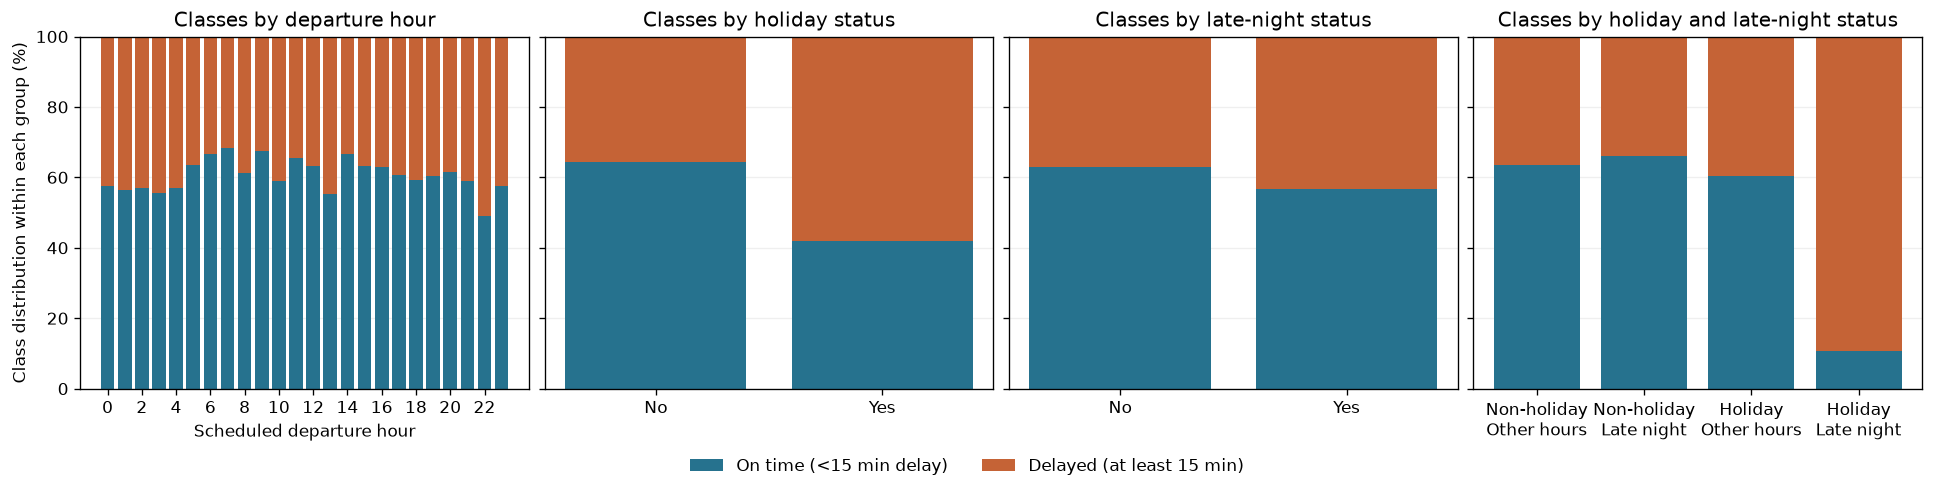

In [ ]:
#| echo: false
#| out-height: "400px"

# Normalize within each group to compare class distributions despite unequal group sizes.
hourly_classes = pd.crosstab(df['departure_hour'], df['delayed_15_min']).reindex(
    index=range(24), columns=[0, 1], fill_value=0,
)
is_holiday_classes = pd.crosstab(df['is_holiday'], df['delayed_15_min']).reindex(
    index=range(2), columns=[0, 1], fill_value=0,
)
is_late_night_classes = pd.crosstab(df['is_late_night'], df['delayed_15_min']).reindex(
    index=range(2), columns=[0, 1], fill_value=0,
)
interaction_classes = pd.crosstab(
    [df['is_holiday'], df['is_late_night']], df['delayed_15_min'],
).reindex(
    index=pd.MultiIndex.from_product([[0, 1], [0, 1]], names=['is_holiday', 'is_late_night']),
    columns=[0, 1], fill_value=0,
)
hourly_shares = hourly_classes.div(hourly_classes.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
is_holiday_shares = is_holiday_classes.div(is_holiday_classes.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
is_late_night_shares = is_late_night_classes.div(is_late_night_classes.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
interaction_shares = interaction_classes.div(interaction_classes.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True, layout='constrained')
for ax, shares in zip(axes, [hourly_shares, is_holiday_shares, is_late_night_shares, interaction_shares]):
    positions = np.arange(len(shares))
    ax.bar(positions, shares[0], color='#26728e', label='On time (<15 min delay)')
    ax.bar(positions, shares[1], bottom=shares[0], color='#c56336', label='Delayed (at least 15 min)')
    ax.set(ylim=(0, 100))
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.2)

axes[0].set(xlabel='Scheduled departure hour', ylabel='Class distribution within each group (%)', title='Classes by departure hour', xticks=range(0, 24, 2))
interaction_labels = ['Non-holiday\nOther hours', 'Non-holiday\nLate night', 'Holiday\nOther hours', 'Holiday\nLate night']
axes[1].set(xticks=range(2), xticklabels=["No", "Yes"], title='Classes by holiday status')
axes[2].set(xticks=range(2), xticklabels=["No", "Yes"], title='Classes by late-night status')
axes[3].set(xticks=range(4), xticklabels=interaction_labels, title='Classes by holiday and late-night status')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=2, frameon=False)
plt.show()


# Data understanding and visualization

In [ ]:
#| echo: false
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def check_correlations(X, y, include_actual_times=True, thr=0.6):
    # Combine engineered X and target y
    df_corr = pd.concat(
        [
            FlightFeatureEngineer(
                add_manual_features=True,
                include_actual_times=include_actual_times,
                drop_datetime=False,
            ).transform(X),
            y,
        ],
        axis=1,
    ).copy()

    # Convert datetime columns to Unix timestamps in seconds
    for col in df_corr.select_dtypes(include=["datetime", "datetime64"]).columns:
        df_corr[col] = df_corr[col].astype("int64") // 10**9

    # Compute correlation matrix
    corr = df_corr.corr(numeric_only=True)

    # Ignore identity correlations
    non_identity = ~np.eye(len(corr), dtype=bool)

    # Keep variables with at least one non-identity |correlation| > thr
    keep = (corr.abs().gt(thr) & non_identity).any(axis=1)

    # Always retain the y column(s)
    y_columns = [y.name] if isinstance(y, pd.Series) else list(y.columns)
    keep.loc[corr.index.intersection(y_columns)] = True

    filtered_corr = corr.loc[keep, keep]

    # Plot filtered correlation matrix
    if filtered_corr.empty:
        print(f"No non-identity correlations with |correlation| > {thr}.")
    else:
        plt.figure(figsize=(12, 9))
        sns.heatmap(
            filtered_corr,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            vmin=-1,
            vmax=1,
            linewidths=0.5,
        )
        plt.title(f"Variables with at least one |correlation| > {thr}")
        plt.tight_layout()
        plt.show()

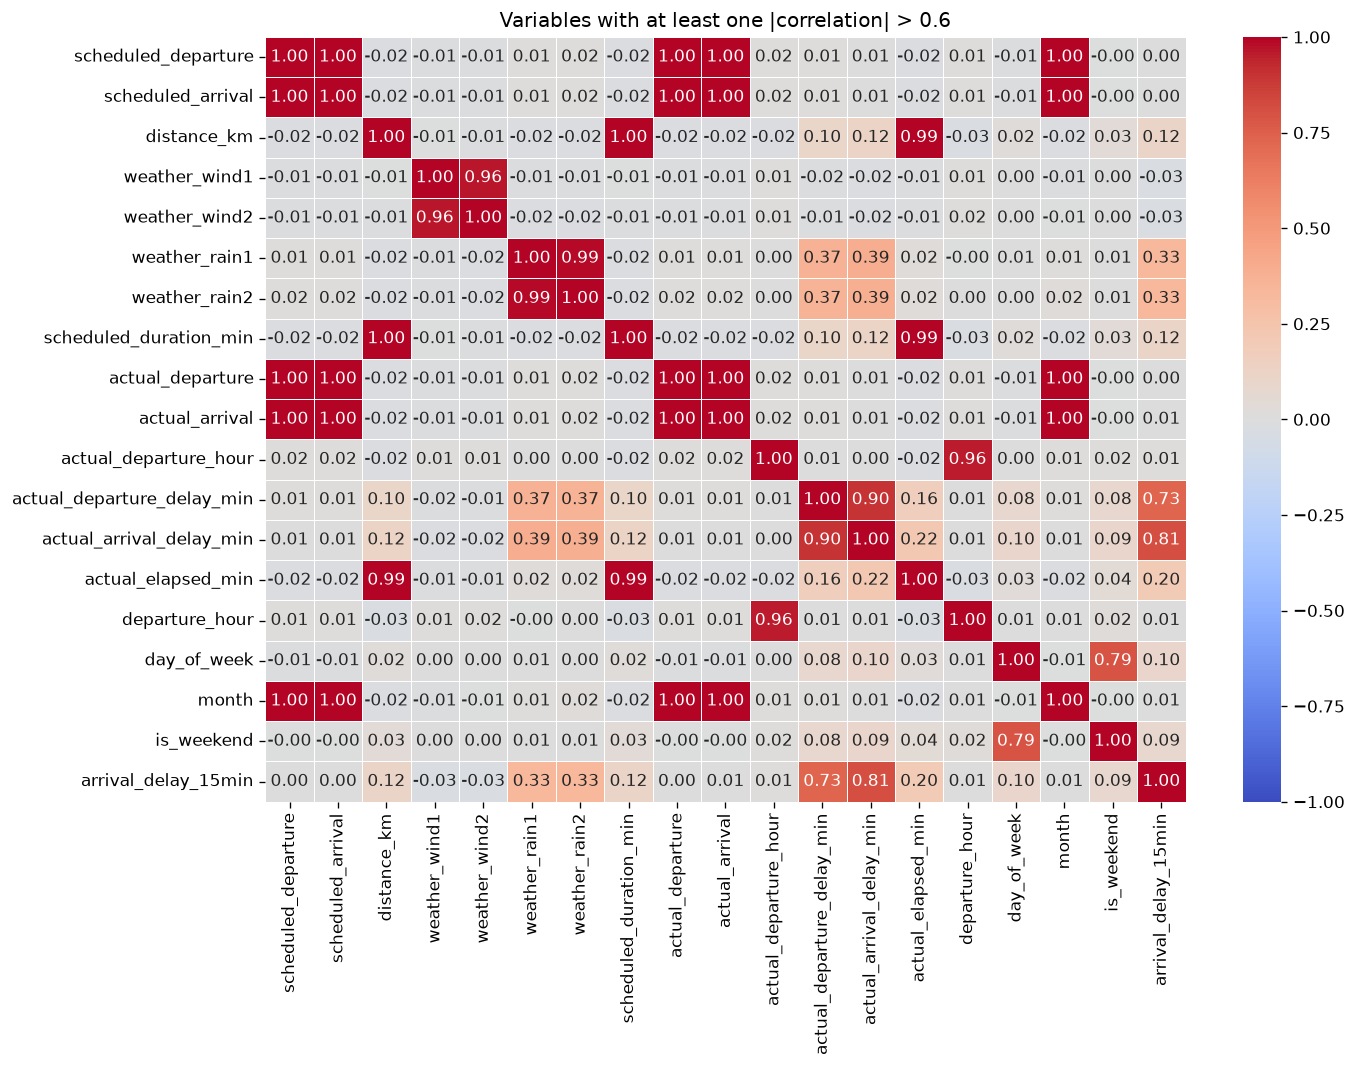

In [ ]:
#| echo: false

check_correlations(X, y)

# Data understanding and visualization

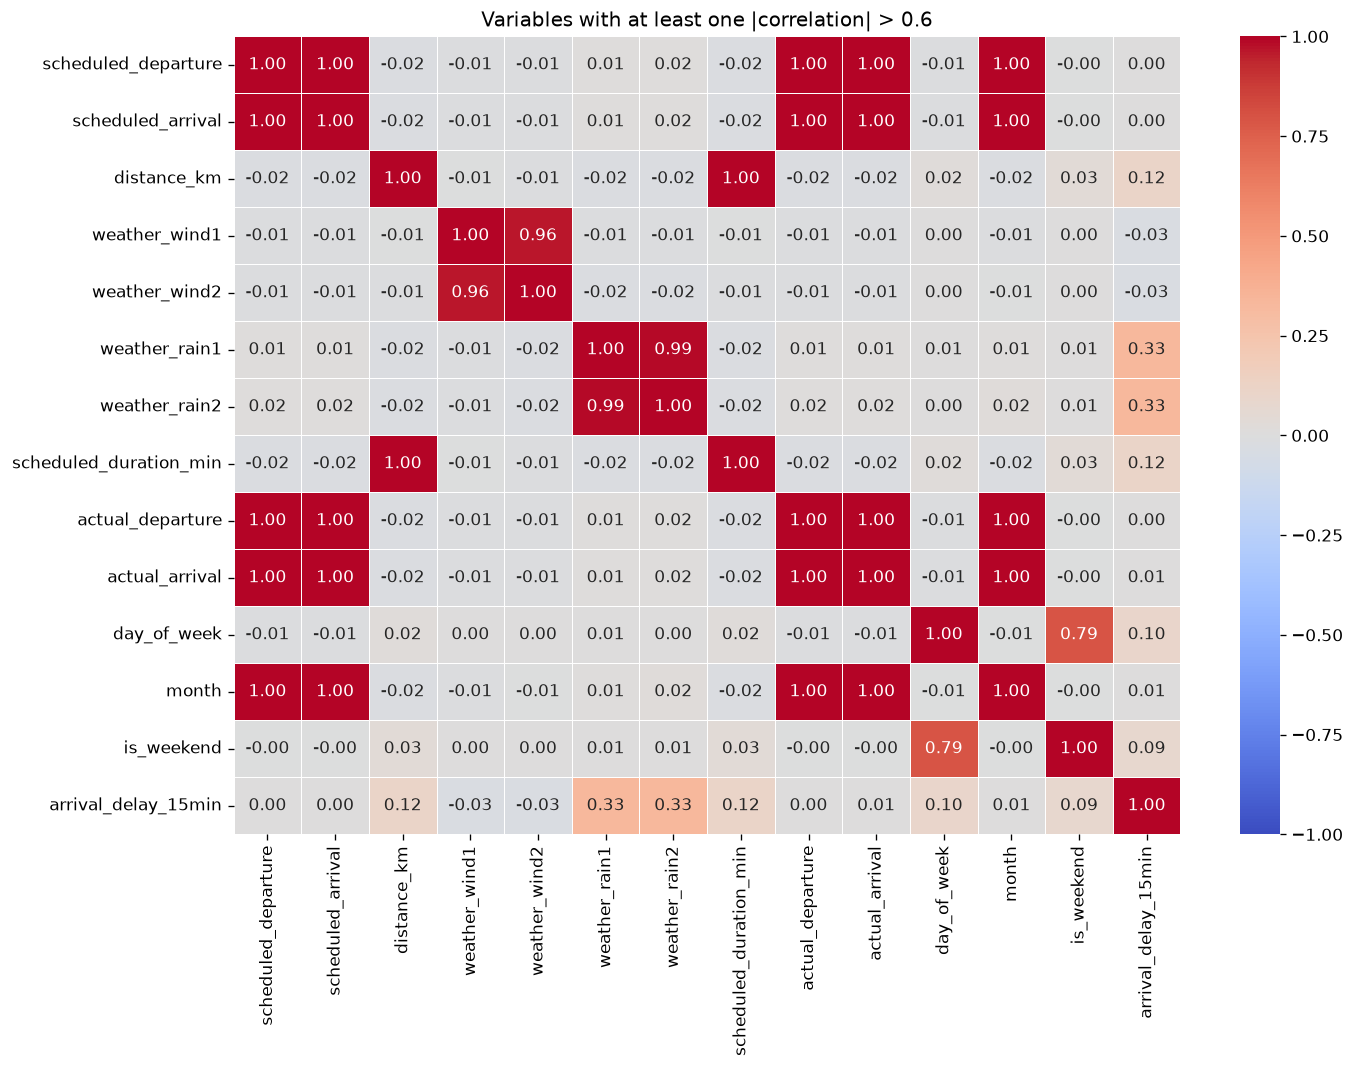

In [ ]:
#| echo: false

check_correlations(X, y, include_actual_times=False)

# Are features known at prediction time?


In [ ]:
#| echo: false
# Compare safe and leaky engineered schemas before fitting any model.
safe_engineered_view = FlightFeatureEngineer(add_manual_features=True, include_actual_times=False, drop_datetime=False,).transform(X)
leaky_engineered_view = FlightFeatureEngineer(add_manual_features=True, include_actual_times=True).transform(X)

manual_feature_names = {
    "departure_hour", "day_of_week", "month", "is_weekend", "is_holiday", "is_late_night",
    "km_per_minute", "mean_wind_kmh", "mean_rain_mm", "wind_forecast_gap", "rain_forecast_gap",
    "high_precipitation", "holiday_late_night", "sfo_long_route", "route",
}
actual_time_feature_names = {
    "actual_departure", "actual_arrival", "actual_departure_hour", "actual_arrival_hour",
    "actual_departure_delay_min", "actual_arrival_delay_min", "actual_elapsed_min",
}

availability_notes = {
    "scheduled_departure": "before departure",
    "scheduled_arrival": "before departure",
    "actual_departure": "after departure",
    "actual_arrival": "after arrival",
    "actual_departure_hour": "after departure",
    "actual_arrival_hour": "after arrival",
    "actual_departure_delay_min": "after departure",
    "actual_arrival_delay_min": "after arrival",
    "actual_elapsed_min": "after arrival",
}

all_schema_columns = list(dict.fromkeys(list(X.columns) + list(leaky_engineered_view.columns)))
schema_rows = []

for column in all_schema_columns:
    if column in X.columns:
        dtype = X[column].dtype
        source = "raw"
    else:
        dtype = leaky_engineered_view[column].dtype
        source = "engineered"

    if column in actual_time_feature_names:
        keep_for_predeparture = "drop"
        leakage_risk = "high"
    elif column in safe_engineered_view.columns or column in X.columns:
        keep_for_predeparture = "candidate"
        leakage_risk = "low"
    else:
        keep_for_predeparture = "review"
        leakage_risk = "unknown"

    if column in actual_time_feature_names:
        selection_comment = "May score very high, but must be excluded because it is future information."
    elif column in manual_feature_names:
        selection_comment = "SelectKBest keeps it only if its mutual-information score is among the top k."
    else:
        selection_comment = "Candidate feature; keep only if available at prediction time and useful."

    schema_rows.append({
        "feature": column,
        "dtype": str(dtype),
        "source": source,
        "availability": availability_notes.get(column, "before departure"),
        "feature_family": "actual-time leakage" if column in actual_time_feature_names else "manual/domain" if column in manual_feature_names else "raw input",
        "predeparture_decision": keep_for_predeparture,
        "leakage_risk": leakage_risk,
        "selection_comment": selection_comment,
    })

feature_schema = pd.DataFrame(schema_rows)
schema_display_columns = ["feature", "dtype", "source", "availability"]
feature_schema.loc[feature_schema["source"] == "raw", schema_display_columns].sort_values(by=["availability", "source"], ascending=False)

# print("Safe engineered dataframe shape:", safe_engineered_view.shape)
# print("With actual-time features shape:", leaky_engineered_view.shape)

,feature,dtype,source,availability
0,scheduled_departure,datetime64[us],raw,before departure
1,scheduled_arrival,datetime64[us],raw,before departure
2,carrier,str,raw,before departure
3,origin,str,raw,before departure
4,destination,str,raw,before departure
5,distance_km,int64,raw,before departure
6,weather_wind1,float64,raw,before departure
7,weather_wind2,float64,raw,before departure
8,weather_rain1,float64,raw,before departure
9,weather_rain2,float64,raw,before departure


# Are features known at prediction time?

In [ ]:
#| echo: false
feature_schema.loc[feature_schema["source"] == "engineered", schema_display_columns].sort_values(by=["availability", "source"], ascending=False)

,feature,dtype,source,availability
21,departure_hour,int32,engineered,before departure
22,day_of_week,int32,engineered,before departure
23,month,int32,engineered,before departure
24,is_weekend,int64,engineered,before departure
25,is_holiday,int64,engineered,before departure
26,airport_ATL,int64,engineered,before departure
27,airport_BOS,int64,engineered,before departure
28,airport_JFK,int64,engineered,before departure
29,airport_LAX,int64,engineered,before departure
30,airport_SFO,int64,engineered,before departure


# Pipeline generation

In [ ]:
#| echo: false
# Build reusable preprocessing and classifier helpers for the later experiments.
def numeric_columns(X):
    return X.select_dtypes(include=np.number).columns.tolist()


def categorical_columns(X):
    return X.select_dtypes(exclude=np.number).columns.tolist()


def make_preprocessor():
    try:
        one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

    return ColumnTransformer(
        transformers=[
            ("num", "passthrough", numeric_columns),
            ("cat", one_hot, categorical_columns),
        ],
        verbose_feature_names_out=False,
    )


def make_tree(max_depth=5, min_samples_leaf=1):
    return DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, class_weight="balanced", random_state=RANDOM_STATE)

def mutual_info_reproducible(X_array, y_array):
    return mutual_info_classif(X_array, y_array, random_state=RANDOM_STATE)


def make_pipeline(add_manual_features=False, include_actual_times=False, selector=None):
    steps = [
        ("feature_engineering", FlightFeatureEngineer(add_manual_features=add_manual_features, include_actual_times=include_actual_times)),
        ("preprocessing", make_preprocessor().set_output(transform="pandas")
            if isinstance(selector, Pipeline) else make_preprocessor()),
    ]
    if selector is not None:
        steps.append(("feature_selection", selector)) # Selection is part of model fitting. Keeping it inside the pipeline prevents validation-fold information from guiding the selected features.
    steps.append(("classifier", make_tree()))
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "balanced_accuracy": make_scorer(balanced_accuracy_score),
    "f1": make_scorer(f1_score),
}
make_pipeline(add_manual_features=False)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessing', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,add_manual_features,False
,include_actual_times,False
,drop_datetime,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be for

# Actual departure and arrival times: keep or drop?

Prediction time matters:

- *Ticket sale*: route, carrier, scheduled times, and planned distance/duration.
- *Morning of travel*: forecasts and known schedule pressure.
- *Gate before departure*: current weather and operational status that is already known.
- *After departure*: actual departure time and departure delay may be inferred.
- *After landing*: actual arrival time and arrival delay are known.


In [ ]:
#| echo: false
# Demonstrate how future information can inflate validation metrics.
leakage_demo = {
    "Raw data - no feature engineering": make_pipeline(add_manual_features=False),
    "Feature engineering": make_pipeline(add_manual_features=True),
    "Leaky feature engineering": make_pipeline(add_manual_features=True, include_actual_times=True),
}
leakage_rows = []
for name, estimator in leakage_demo.items():
    result = cross_validate(estimator, X, y, cv=cv, scoring=scoring, n_jobs=-1, return_estimator=True,)
    leakage_rows.append({
        "experiment": name,
        "balanced_accuracy_mean": result["test_balanced_accuracy"].mean(),
        "f1_mean": result["test_f1"].mean(),
    })


pd.DataFrame(leakage_rows)


,experiment,balanced_accuracy_mean,f1_mean
0,Raw data - no feature engineering,0.757822,0.702689
1,Feature engineering,0.790393,0.745900
2,Leaky feature engineering,1.000000,1.000000


# Leakage can make perfect predictions, but it is not useful in practice.

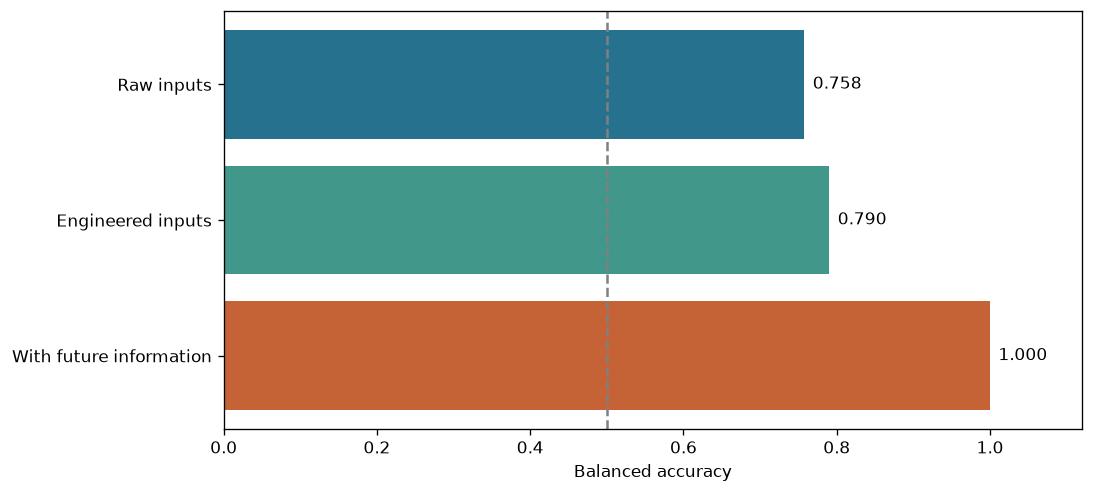

In [ ]:
#| echo: false
#| out-height: "400px"

leakage_plot = pd.DataFrame(leakage_rows)
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
bars = ax.barh(['Raw inputs', 'Engineered inputs', 'With future information'],
               leakage_plot['balanced_accuracy_mean'], color=['#26728e', '#419789', '#c56336'])
ax.bar_label(bars, fmt='%.3f', padding=5)
ax.axvline(0.5, color='gray', linestyle='--')
ax.set(xlim=(0, 1.12), xlabel='Balanced accuracy',)
ax.invert_yaxis()
plt.show()


# Automated feature selection

![Filter Methods](https://upload.wikimedia.org/wikipedia/commons/2/2c/Filter_Methode.png?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail_unscaled)

**Filter methods** rank features using a statistical criterion independent of the final model.

- Filter methods are usually faster. *Why?*
- Variance and correlation filters inspect predictors without using the target.
- We then use mutual information with `SelectKBest`.

# Filter: low variance

`VarianceThreshold` removes predictors that vary too little in the training data. *Why*?

- `threshold=0` removes constants; a positive threshold also removes low-variance features.
- Variance depends on units; do not first scale every feature to unit variance.
- The filter ignores the target: a rare binary predictor can have low variance and still be useful.

```python
from sklearn.feature_selection import VarianceThreshold
variance_filter = VarianceThreshold(threshold=0.01)
```

[VarianceThreshold documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.VarianceThreshold.html)


# Variance filter: inspect the removals

In [ ]:
#| echo: false
from sklearn.feature_selection import VarianceThreshold
filter_plot_train, _, filter_plot_y, _ = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE,
)
filter_preprocessing = make_pipeline(add_manual_features=True)[:-1]
filter_values = filter_preprocessing.fit_transform(filter_plot_train, filter_plot_y)
filter_features = pd.DataFrame(
    filter_values, index=filter_plot_train.index,
    columns=filter_preprocessing.named_steps["preprocessing"].get_feature_names_out(),
)
variance_filter = VarianceThreshold(threshold=0.01).fit(filter_features)
variance_example = pd.DataFrame({"training_variance": variance_filter.variances_, "retained": variance_filter.get_support(),}, index=filter_features.columns)
print(f"Input features: {filter_features.shape[1]}; retained: {variance_filter.get_support().sum()} (threshold=0.01).")
variance_example.sort_values("training_variance").head().round(4)


Input features: 34; retained: 34 (threshold=0.01).


,training_variance,retained
is_holiday,0.1375,True
origin_SFO,0.1532,True
destination_ATL,0.1557,True
carrier_B6,0.1562,True
carrier_DL,0.1574,True


# Filter: high correlation

`DropCorrelatedFeatures` removes redundant numeric predictors.

- With `threshold=0.9`, remove features whose absolute correlation with a retained feature exceeds 0.9.
    - Absolute correlation catches both positive and negative relationships.
- By default, Pearson correlation measures linear association between predictors, not association with the target.
- Column order can affect which representative survives.
    - Correlation alone does not identify the most predictive representative.

```python
from feature_engine.selection import DropCorrelatedFeatures
correlation_filter = DropCorrelatedFeatures(threshold=0.9)
```

[DropCorrelatedFeatures documentation](https://feature-engine.trainindata.com/en/latest/user_guide/selection/DropCorrelatedFeatures.html)


# Correlation filter: inspect the redundant pairs

In [ ]:
#| echo: false

import importlib.util
import subprocess
import sys

if importlib.util.find_spec("feature_engine") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "feature-engine"])
from feature_engine.selection import DropCorrelatedFeatures

correlation_filter = DropCorrelatedFeatures(threshold=0.9).fit(filter_features)
correlation_example = pd.DataFrame([
    {"retained": kept, "removed": removed,
     "absolute_correlation": abs(filter_features[kept].corr(filter_features[removed]))}
    for kept, redundant in correlation_filter.correlated_feature_dict_.items()
    for removed in sorted(redundant)
])
print(f"Input features: {filter_features.shape[1]}; removed: {len(correlation_filter.features_to_drop_)} (threshold=0.9).")
correlation_example.round(3)


Input features: 34; removed: 3 (threshold=0.9).


,retained,removed,absolute_correlation
0,distance_km,scheduled_duration_min,1.000
1,weather_rain1,weather_rain2,0.989
2,weather_wind1,weather_wind2,0.964


In [325]:
#| echo: false
#| output: false
combined_filters = Pipeline([
    ("variance", VarianceThreshold(threshold=0.01).set_output(transform="pandas")),
    ("correlation", DropCorrelatedFeatures(threshold=0.9)),
])
filtered_feature_train = combined_filters.fit_transform(filter_features)
pd.DataFrame({
    "input_features": [filter_features.shape[1]],
    "after_variance": [len(combined_filters.named_steps["variance"].get_feature_names_out())],
    "after_correlation": [filtered_feature_train.shape[1]],
})


,input_features,after_variance,after_correlation
0,34,34,31


In [ ]:
#| echo: false
def make_filter_selector(k):
    return Pipeline([
        *clone(combined_filters).steps,
        ("kbest", SelectKBest(score_func=mutual_info_reproducible, k=k)),
    ])


# Filter: `SelectKBest`

`SelectKBest` ranks features by `score_func` and keeps the top `k`.

- Each feature is scored separately.
- With `mutual_info_classif`, keep the features with the highest estimated mutual information (MI) with the class label.
    - MI is non-negative; zero suggests little dependence between the feature and target.
    - Larger MI means the feature reduces more uncertainty about the label.
- Useful combinations can be missed, and redundant features can survive. *Why?*

```python
SelectKBest(score_func=mutual_info, k=8)
```


# Compare candidate feature counts `k`

In [ ]:
#| echo: false
k_values = np.linspace(5, filtered_feature_train.shape[1], 10, dtype=int)
curve_rows = []
for k in k_values:
    estimator = make_pipeline(add_manual_features=True, selector=make_filter_selector(k),)
    result = cross_validate(estimator, X, y, cv=cv, scoring={"balanced_accuracy": make_scorer(balanced_accuracy_score)}, n_jobs=-1,)
    curve_rows.append({ "k": k, "balanced_accuracy_mean": result["test_balanced_accuracy"].mean(), "balanced_accuracy_std": result["test_balanced_accuracy"].std(), })
k_curve = pd.DataFrame(curve_rows)
k_curve

,k,balanced_accuracy_mean,balanced_accuracy_std
0,5,0.716955,0.015365
1,7,0.715234,0.015562
2,10,0.716800,0.015527
3,13,0.749792,0.034429
4,16,0.767447,0.027305
5,19,0.765352,0.026954
6,22,0.771642,0.034421
7,25,0.772301,0.034401
8,28,0.778533,0.028552
9,31,0.789586,0.020354


# Elbow method: choose the "right" `k`.

Choose the point after which extra features give diminishing returns.

- A smaller model may be preferable when its accuracy loss is negligible.

<div></div>

In [ ]:
#| echo: false
#| output: false
# Geometric elbow: point farthest above the line connecting first and last scores.
x = k_curve["k"].to_numpy(dtype=float)
y_score = k_curve["balanced_accuracy_mean"].to_numpy(dtype=float)
x_norm = (x - x.min()) / (x.max() - x.min())
y_range = y_score.max() - y_score.min()
y_norm = np.zeros_like(y_score) if y_range == 0 else (y_score - y_score.min()) / y_range
line = np.column_stack([x_norm, y_norm])
start = line[0]
end = line[-1]
line_vector = end - start
point_vectors = start - line
distances = np.abs(
    line_vector[0] * point_vectors[:, 1] - line_vector[1] * point_vectors[:, 0]
) / np.linalg.norm(line_vector)

elbow_index = int(np.argmax(distances))
elbow_k = int(k_curve.loc[elbow_index, "k"])
n_features_to_select = 8
k_curve.assign(elbow_score=distances).round(3)


,k,balanced_accuracy_mean,balanced_accuracy_std,elbow_score
0,5,0.717,0.015,0.000
1,7,0.715,0.016,0.070
2,10,0.717,0.016,0.136
3,13,0.750,0.034,0.101
4,16,0.767,0.027,0.190
5,19,0.765,0.027,0.089
6,22,0.772,0.034,0.069
7,25,0.772,0.034,0.005
8,28,0.779,0.029,0.026
9,31,0.790,0.020,0.000


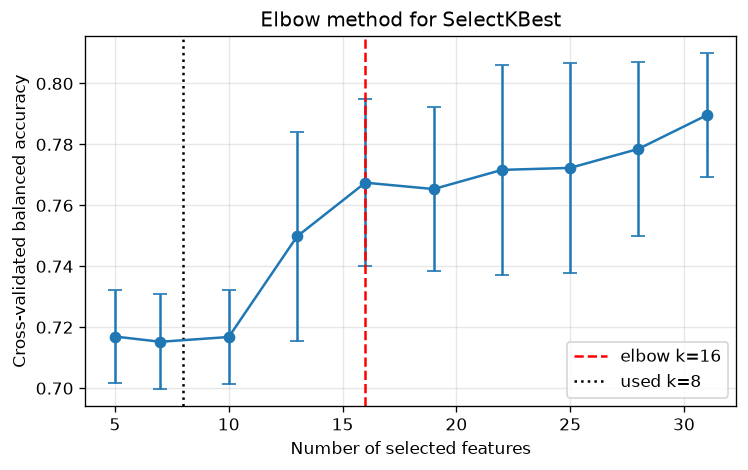

In [ ]:
#| echo: false
# Show the elbow curve used to select k.
plt.figure(figsize=(7, 4))
plt.errorbar(k_curve["k"], k_curve["balanced_accuracy_mean"], yerr=k_curve["balanced_accuracy_std"], marker="o", capsize=4)
plt.axvline(elbow_k, color="red", linestyle="--", label=f"elbow k={elbow_k}")
plt.axvline(n_features_to_select, color="black", linestyle=":", label=f"used k={n_features_to_select}")
plt.xlabel("Number of selected features")
plt.ylabel("Cross-validated balanced accuracy")
plt.title("Elbow method for SelectKBest")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
#| echo: false

filter_selector = make_filter_selector(n_features_to_select)


# What does the filter keep?

- Fit SelectKBest on the features retained by variance and correlation filtering.
    - Color marks retained features; only some features tied at the boundary may be selected.
- These are training scores, not validation performance.


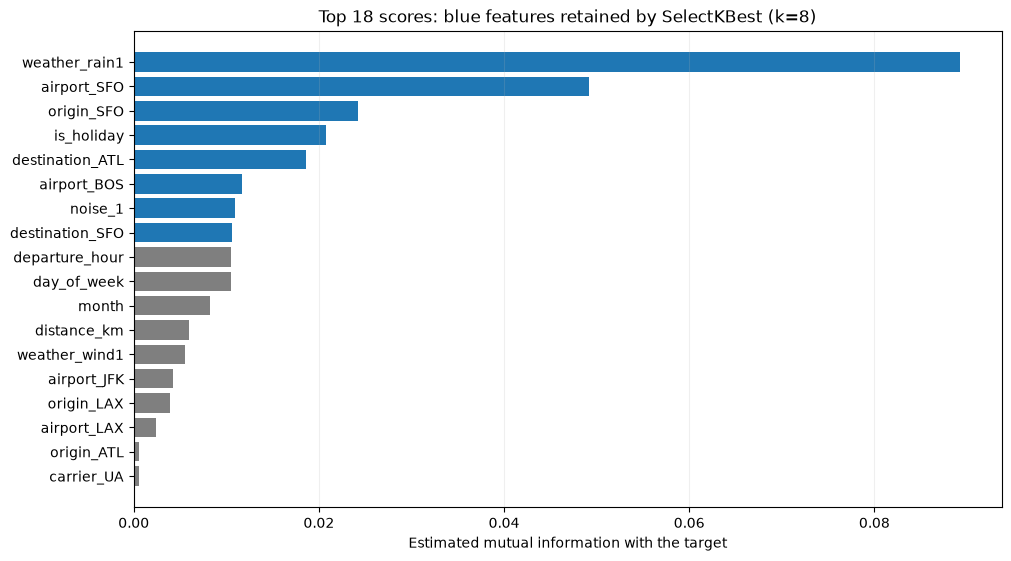

In [326]:
#| echo: false
#| out-height: "400px"

filter_plot_selector = SelectKBest(
    score_func=mutual_info_reproducible, k=n_features_to_select,
).fit(filtered_feature_train, filter_plot_y)
filter_plot_scores = pd.DataFrame({
    'feature': filtered_feature_train.columns,
    'score': filter_plot_selector.scores_,
    'selected': filter_plot_selector.get_support(),
}).sort_values('score', ascending=False).head(18).sort_values('score')
fig, ax = plt.subplots(figsize=(10, 5.5), layout='constrained')
ax.barh(filter_plot_scores['feature'], filter_plot_scores['score'],
        color=np.where(filter_plot_scores['selected'], 'tab:blue', 'tab:gray'))
ax.set(xlabel='Estimated mutual information with the target',
       title=f'Top 18 scores: blue features retained by SelectKBest (k={n_features_to_select})')
ax.grid(axis='x', alpha=0.2)
plt.show()


# Automated feature selection

![Wrapper Methods](https://upload.wikimedia.org/wikipedia/commons/0/04/Feature_selection_Wrapper_Method.png?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail_unscaled)

**Wrapper methods** search for a subset by repeatedly fitting a model.

- Wrapper methods can capture model-specific usefulness, but they are more computationally expensive. *Why?*
- Here we use `SequentialFeatureSelector` and `RFE`.

# Wrapper: `SequentialFeatureSelector`

Forward-SFS greedily adds one feature at a time.

- Start with no features.
    - Fit an estimator on each candidate feature and compare cross-validated scores.
    - Keep the best candidate.
- Repeat with each remaining feature added to the selected set.
    - Stop at the desired feature count.

Backward-SFS reverses the search.

- Start with all features and remove one at each step.
- In sklearn, use `SequentialFeatureSelector(direction="backward")`.


In [ ]:
#| echo: false

sfs_selector = SequentialFeatureSelector(estimator=make_tree(), n_features_to_select=n_features_to_select, direction="forward", scoring="balanced_accuracy", cv=3, n_jobs=-1)


# Wrapper: `RFE`

Recursive feature elimination (RFE) repeatedly fits an estimator and removes its least important features.

- The estimator must expose feature weights or importances.
    - A linear model can provide coefficients.
    - A tree can provide feature importances.
- Fit the estimator on the current feature set.
    - Remove the least important features, then fit again.
    - Stop at the desired feature count.


In [ ]:
#| echo: false

rfe_selector = RFE(estimator=make_tree(), n_features_to_select=n_features_to_select, step=0.2)

# RFE versus backward SFS

`RFE` and backward `SequentialFeatureSelector` both remove features until the desired subset size is reached.

- **RFE** uses the fitted estimator's importance signal.
    - Logistic regression usually uses coefficient magnitudes; trees use feature importances.
    - It asks: *which feature does the fitted model consider weakest?*

- **Backward `SequentialFeatureSelector` (SFS)** compares candidate removals using balanced accuracy.
    - Remove the feature that gives the best cross-validated score or hurts it least.
    - It asks: *which feature can I remove while preserving validation performance?*
- RFE is usually faster.
    - Backward SFS is usually more expensive because it directly evaluates candidate subsets.


# Compare raw, engineered, and selected feature sets

In [ ]:
#| echo: false
# Run every feature strategy under the same stratified cross-validation protocol.

experiments = {
    "raw": make_pipeline(add_manual_features=False),
    "fe": make_pipeline(add_manual_features=True),
    "fe + wrapper (SFS)": make_pipeline(add_manual_features=True, selector=sfs_selector),
    "fe + filter (SelectKBest)": make_pipeline(add_manual_features=True, selector=filter_selector),
    "fe + wrapper (RFE)": make_pipeline(add_manual_features=True, selector=rfe_selector),
}


def count_output_features(estimator):
    return len(selected_feature_names_ordered(estimator))


def selected_feature_names_ordered(fitted_pipeline):
    """Return feature names in the exact order seen by the final estimator."""
    names = fitted_pipeline.named_steps["preprocessing"].get_feature_names_out()
    selector = fitted_pipeline.named_steps.get("feature_selection")
    if selector is None:
        return list(names)
    return list(selector.get_feature_names_out(names))


def selected_feature_names(fitted_pipeline):
    return set(selected_feature_names_ordered(fitted_pipeline))


def mean_jaccard(selected_sets):
    scores = []
    for i in range(len(selected_sets)):
        for j in range(i + 1, len(selected_sets)):
            union = selected_sets[i] | selected_sets[j]
            intersection = selected_sets[i] & selected_sets[j]
            scores.append(len(intersection) / len(union))
    return np.mean(scores)


rows = []
cv_results_by_name = {}

for name, estimator in experiments.items():
    start_time = time.perf_counter()
    result = cross_validate(estimator, X, y, cv=cv, scoring=scoring, return_estimator=True, n_jobs=-1)
    elapsed = time.perf_counter() - start_time
    cv_results_by_name[name] = result

    selected_counts = [count_output_features(fitted) for fitted in result["estimator"]]
    selector_was_used = any(
        fitted.named_steps.get("feature_selection") is not None
        for fitted in result["estimator"]
    )
    selected_sets = [selected_feature_names(fitted) for fitted in result["estimator"]]
    stability_jaccard = mean_jaccard(selected_sets) if selector_was_used else np.nan

    rows.append({
        "experiment": name,
        "balanced_accuracy_mean": result["test_balanced_accuracy"].mean(),
        "balanced_accuracy_std": result["test_balanced_accuracy"].std(),
        "f1_mean": result["test_f1"].mean(),
        "f1_std": result["test_f1"].std(),
        "selection_stability_jaccard": stability_jaccard,
        "features_mean": np.mean(selected_counts),
        "features_std": np.std(selected_counts),
        "fit_time_total_sec": elapsed,
    })

summary = pd.DataFrame(rows).sort_values("balanced_accuracy_mean", ascending=False)
summary

,experiment,balanced_accuracy_mean,balanced_accuracy_std,f1_mean,f1_std,selection_stability_jaccard,features_mean,features_std,fit_time_total_sec
4,fe + wrapper (RFE),0.791320,0.019498,0.747075,0.023555,0.911111,8.0,0.0,0.206728
2,fe + wrapper (SFS),0.790923,0.020552,0.746319,0.024987,0.447273,8.0,0.0,9.676408
1,fe,0.790393,0.020539,0.745900,0.024867,NaN,34.0,0.0,0.145069
0,raw,0.757822,0.021924,0.702689,0.027983,NaN,24.0,0.0,0.100686
3,fe + filter (SelectKBest),0.715054,0.015554,0.669056,0.018518,0.393939,8.0,0.0,0.580483


# Compare predictive performance and complexity

- All strategies use the same cross-validation folds.
    - Error bars show the standard deviation across folds, not confidence intervals.
- Compare feature count and fit time alongside accuracy (measured times depend on the machine).


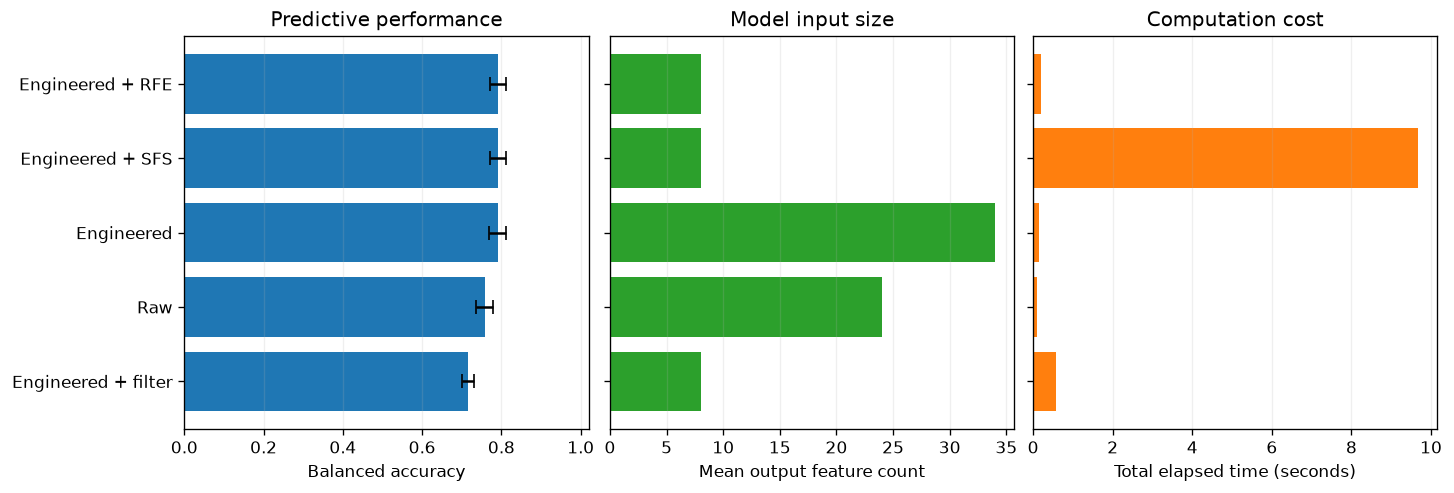

In [ ]:
#| echo: false
#| out-height: "400px"

comparison_plot = summary.sort_values('balanced_accuracy_mean', ascending=False).set_index('experiment')
strategy_labels = comparison_plot.index.map({
    'raw': 'Raw', 'fe': 'Engineered',
    'fe + wrapper (SFS)': 'Engineered + SFS',
    'fe + filter (SelectKBest)': 'Engineered + filter',
    'fe + wrapper (RFE)': 'Engineered + RFE',
})
positions = np.arange(len(strategy_labels))
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, layout='constrained')
axes[0].barh(positions, comparison_plot['balanced_accuracy_mean'],
                 xerr=comparison_plot['balanced_accuracy_std'], capsize=4, color='tab:blue')
axes[0].set(yticks=positions, yticklabels=strategy_labels, xlim=(0, 1.02),
            xlabel='Balanced accuracy', title='Predictive performance')
axes[0].invert_yaxis()
axes[1].barh(positions, comparison_plot['features_mean'], color='tab:green')
axes[1].set(xlabel='Mean output feature count', title='Model input size')
axes[2].barh(positions, comparison_plot['fit_time_total_sec'], color='tab:orange')
axes[2].set(xlabel='Total elapsed time (seconds)', title='Computation cost')
for ax in axes:
    ax.grid(axis='x', alpha=0.2)
plt.show()


# Selection stability across folds

Check whether each selector retains similar features across folds.

- Correlated features can be interchangeable, so changing subsets need not indicate a poor selector.
- Avoid treating selected variables as domain truth when the subset changes across folds.


In [328]:
#| echo: false
# Show which selected-feature methods are stable across validation folds.
stability_rows = []
for name, result in cv_results_by_name.items():
    if "+" not in name:
        continue
    selected_sets = [selected_feature_names(fitted) for fitted in result["estimator"]]
    stability_rows.append({
        "experiment": name,
        "mean_jaccard_similarity": mean_jaccard(selected_sets),
        "example_selected_features": sorted(list(selected_sets[0]))[:15],
    })

stability = pd.DataFrame(stability_rows).sort_values("mean_jaccard_similarity", ascending=False)
stability

,experiment,mean_jaccard_similarity,example_selected_features
2,fe + wrapper (RFE),0.911111,"[airport_SFO, departure_hour, distance_km, is_..."
1,fe + filter (SelectKBest),0.471515,"[airport_SFO, destination_SFO, is_holiday, ori..."
0,fe + wrapper (SFS),0.447273,"[airport_JFK, airport_SFO, carrier_B6, departu..."


# Do the same features survive each fold?

- Each entry shows the fraction of folds that retained a feature.
    - The chart shows the 18 features selected most often across methods.
- Titles report mean pairwise Jaccard similarity over all selected features.
    - Similar accuracy can come from different subsets.


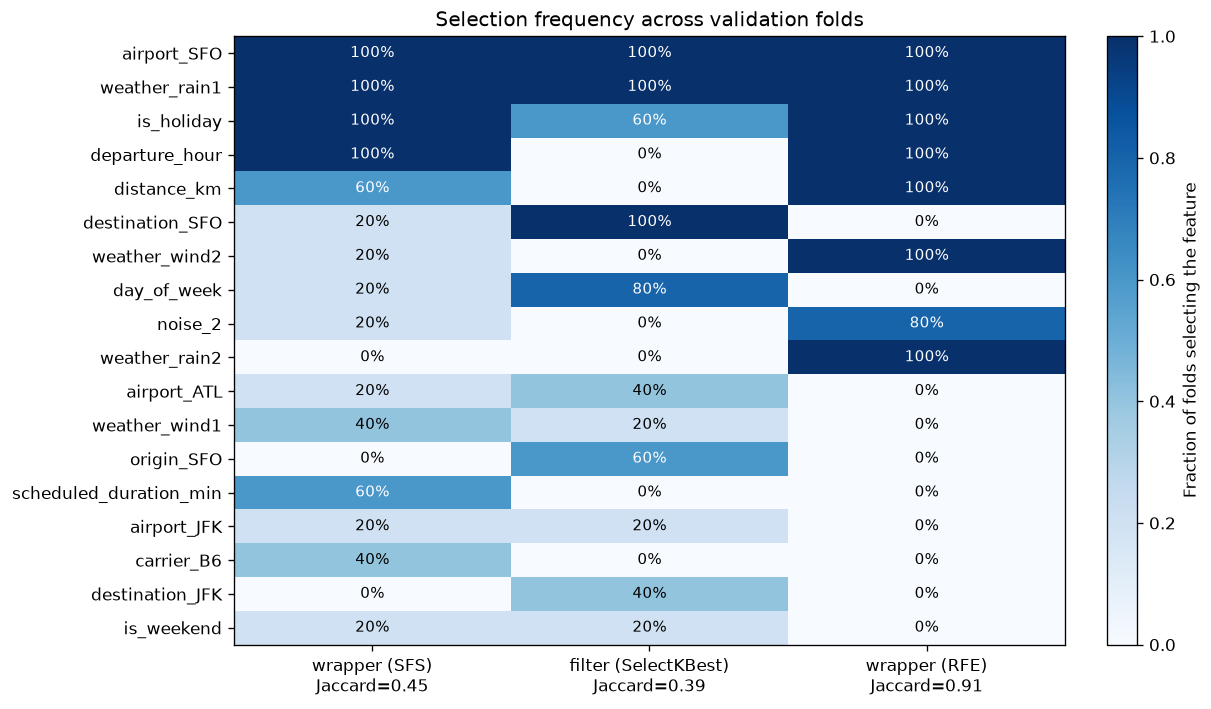

In [ ]:
#| echo: false
#| out-height: "400px"

selection_frequency = {}
selection_jaccard = {}
for method, result in cv_results_by_name.items():
    if result['estimator'][0].named_steps.get('feature_selection') is None:
        continue
    fold_sets = [selected_feature_names(fitted) for fitted in result['estimator']]
    selection_frequency[method] = pd.Series({
        feature: np.mean([feature in selected for selected in fold_sets])
        for feature in sorted(set.union(*fold_sets))
    })
    selection_jaccard[method] = mean_jaccard(fold_sets)
frequency_plot = pd.DataFrame(selection_frequency).fillna(0)
frequency_features = frequency_plot.mean(axis=1).sort_values(ascending=False, kind='stable').head(18).index
frequency_plot = frequency_plot.loc[frequency_features]
fig, ax = plt.subplots(figsize=(10, 5.8), layout='constrained')
image = ax.imshow(frequency_plot, vmin=0, vmax=1, cmap='Blues', aspect='auto')
for row in range(len(frequency_plot)):
    for col in range(len(frequency_plot.columns)):
        value = frequency_plot.iloc[row, col]
        ax.text(col, row, f'{value:.0%}', ha='center', va='center', fontsize=9,
                color='white' if value > 0.55 else 'black')
ax.set(yticks=range(len(frequency_plot)), yticklabels=frequency_plot.index,
       xticks=range(len(frequency_plot.columns)),
       xticklabels=[f'{name.replace("fe + ", "")}\nJaccard={selection_jaccard[name]:.2f}' for name in frequency_plot.columns],
       title='Selection frequency across validation folds')
fig.colorbar(image, ax=ax, label='Fraction of folds selecting the feature')
plt.show()


# Interpretability check

In [ ]:
X_interpret_train, X_interpret_valid, y_interpret_train, y_interpret_valid = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE,)
chosen_pipeline = make_pipeline(add_manual_features=True, selector=rfe_selector)
chosen_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('preprocessing', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,add_manual_features,True
,include_actual_times,False
,drop_datetime,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be form

# Interpretability check

In [334]:
chosen_pipeline.fit(X_interpret_train, y_interpret_train)
selected_feature_names_for_tree = selected_feature_names_ordered(chosen_pipeline)
tree = chosen_pipeline.named_steps["classifier"]
print("Validation balanced accuracy:", round(balanced_accuracy_score(y_interpret_valid, chosen_pipeline.predict(X_interpret_valid)), 3))
pd.DataFrame({
    "feature": selected_feature_names_for_tree,
    "importance": tree.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)

Validation balanced accuracy: 0.776


,feature,importance
0,weather_rain1,0.348670
1,airport_SFO,0.225655
2,distance_km,0.185170
3,departure_hour,0.109938
4,is_holiday,0.087510
5,weather_rain2,0.019028
6,weather_wind2,0.014674
7,noise_3,0.009355


# Plotting the tree

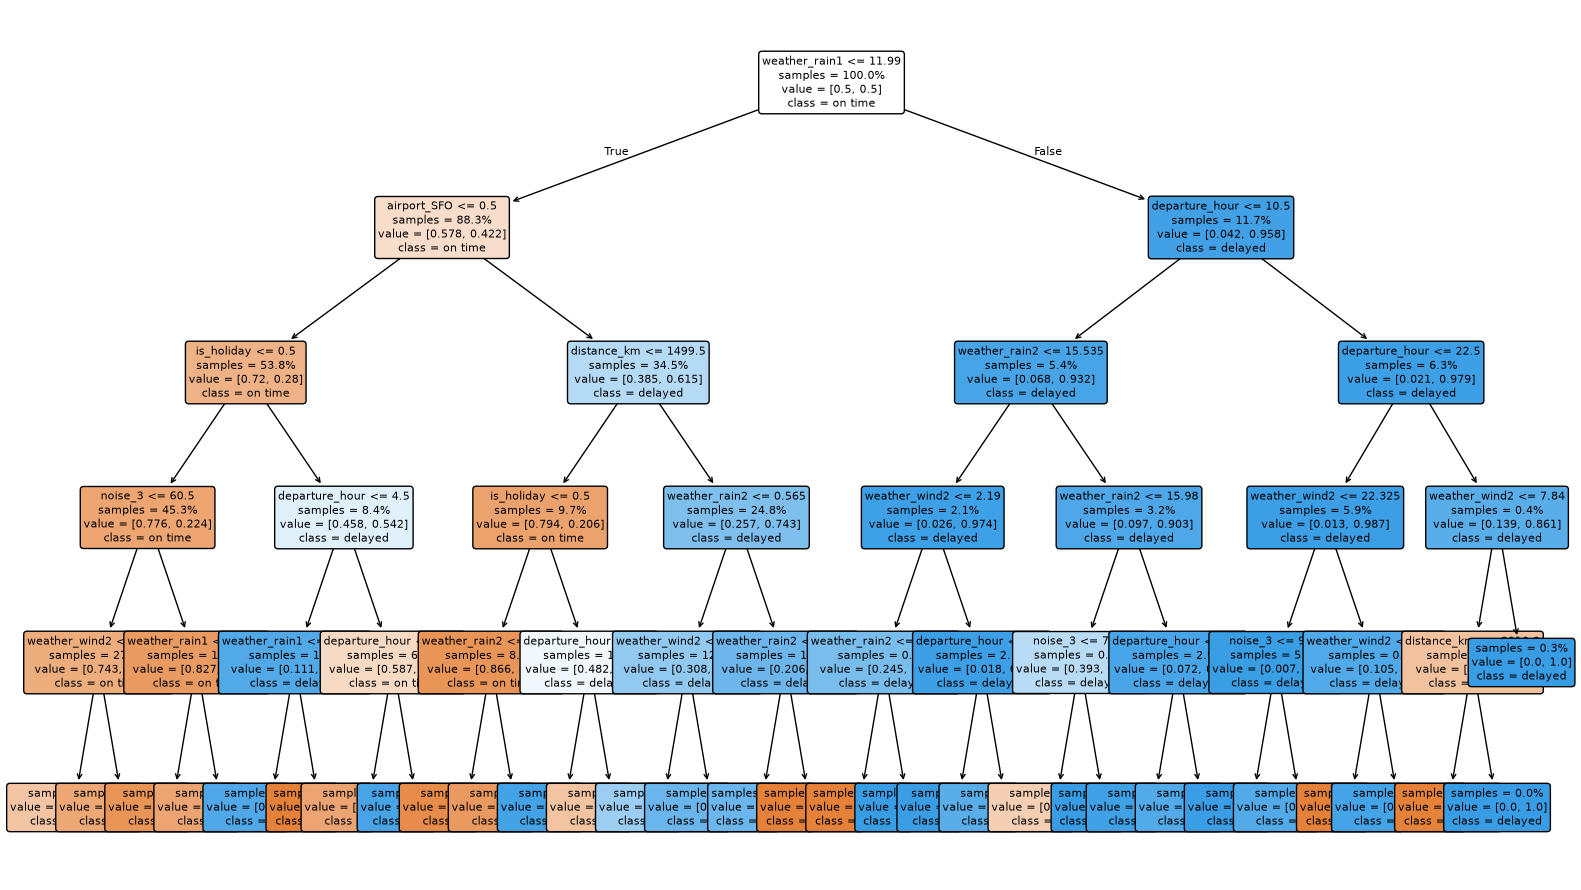

In [333]:
#| echo: false
plt.figure(figsize=(16, 9))
plot_tree(tree, feature_names=selected_feature_names_for_tree, class_names=["on time", "delayed"], filled=True, rounded=True, proportion=True, impurity=False, fontsize=8,)
plt.tight_layout()
plt.show()

# Selected does not always mean used

A selector admits candidate features, but the tree may use only some of them.

- Zero importance means the fitted tree never split on that feature.


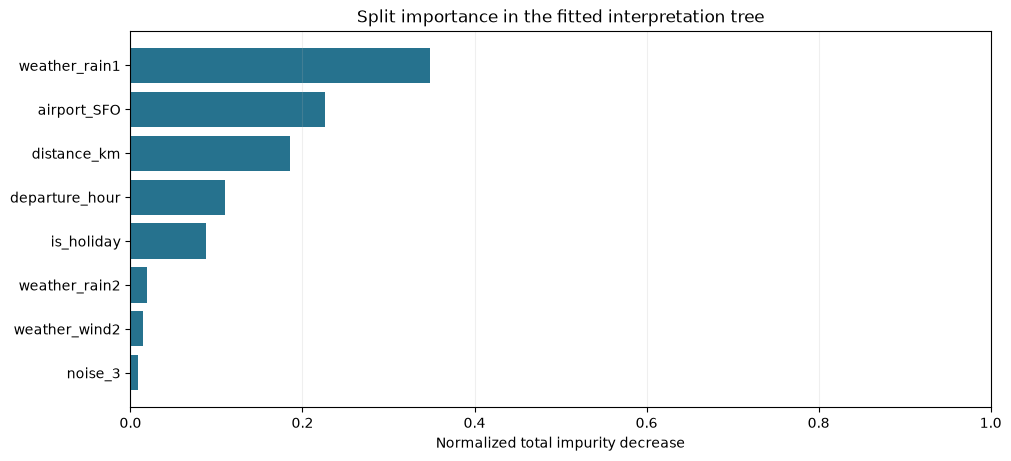

In [335]:
#| echo: false
#| out-height: "400px"

tree_importance_plot = pd.Series(
    tree.feature_importances_, index=selected_feature_names_for_tree,
).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
ax.barh(tree_importance_plot.index, tree_importance_plot.values, color='#26728e')
ax.set(xlabel='Normalized total impurity decrease', xlim=(0, 1),
       title='Split importance in the fitted interpretation tree')
ax.grid(axis='x', alpha=0.2)
plt.show()


# Permutation importance

How much does validation balanced accuracy fall when we shuffle one feature?

- Positive values indicate that shuffling hurts the score; values near zero indicate little measured effect.

```python
from sklearn.inspection import permutation_importance
importance = permutation_importance(
    tree, X_tree_valid.to_numpy(), y_interpret_valid,
    scoring="balanced_accuracy", n_repeats=10,
    random_state=RANDOM_STATE, n_jobs=-1,
)
```

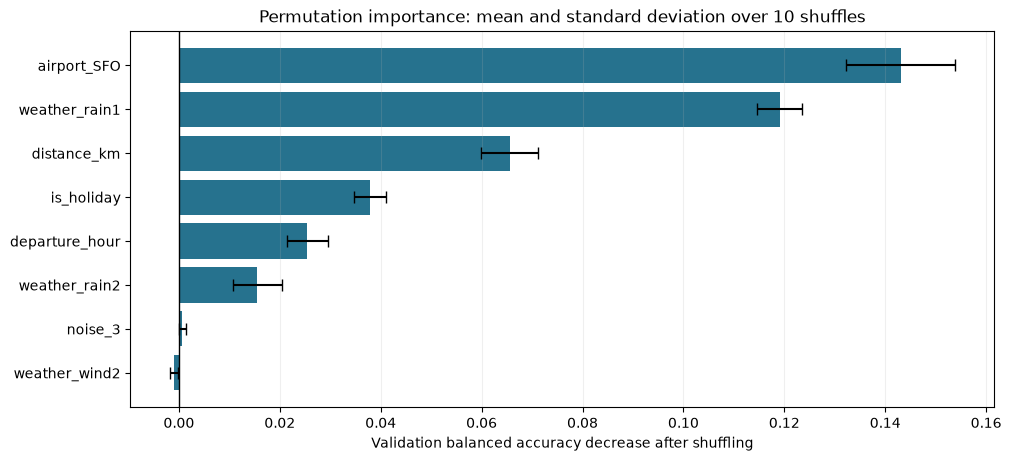

In [336]:
#| echo: false
# Apply every fitted transformation in order, including feature selection.
def tree_input_frame(fitted_pipeline, X_rows):
    values = fitted_pipeline[:-1].transform(X_rows)
    return pd.DataFrame(
        values,
        columns=selected_feature_names_ordered(fitted_pipeline),
        index=X_rows.index,
    )

X_tree_train = tree_input_frame(chosen_pipeline, X_interpret_train)
X_tree_valid = tree_input_frame(chosen_pipeline, X_interpret_valid)
importance = permutation_importance(
    tree, X_tree_valid.to_numpy(), y_interpret_valid,
    scoring="balanced_accuracy", n_repeats=10,
    random_state=RANDOM_STATE, n_jobs=-1,
)
importance_table = pd.DataFrame({
    "tree_feature": selected_feature_names_for_tree,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std,
}).sort_values("importance_mean", ascending=False)
permutation_plot = importance_table.sort_values('importance_mean')
fig, ax = plt.subplots(figsize=(10, 4.5), layout='constrained')
ax.barh(permutation_plot['tree_feature'], permutation_plot['importance_mean'],
        xerr=permutation_plot['importance_std'], capsize=4, color='#26728e')
ax.axvline(0, color='black', linewidth=1)
ax.set(xlabel='Validation balanced accuracy decrease after shuffling',
       title='Permutation importance: mean and standard deviation over 10 shuffles')
ax.grid(axis='x', alpha=0.2)
plt.show()


# SHAP: the contribution of each feature

**SHAP** assigns contributions to a prediction.

For the delayed class (`y=1`), we explain the model's prediction probability: $\hat{P}(y=1 \mid x) = \text{base value} + \sum_{j=1}^{p} \phi_j(x).$

- Positive contributions raise the prediction above the baseline; negative contributions lower it.
- SHAP explains the fitted model, not causal effects.

In [ ]:
#| echo: false

# Install SHAP only if it is missing (also works in Colab).
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("shap") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap>=0.45"])

import shap

In [ ]:
background = X_tree_train.sample(n=min(100, len(X_tree_train)), random_state=RANDOM_STATE) # Use training rows as the background and explain validation rows only.
X_explain = X_tree_valid.sample(n=min(300, len(X_tree_valid)), random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(
    tree,
    data=background,
    feature_names=selected_feature_names_for_tree,
    feature_perturbation="interventional",
    model_output="probability",
)
all_class_shap = explainer(X_explain)
delayed_class_index = int(np.flatnonzero(tree.classes_ == 1)[0])
shap_delayed = all_class_shap[:, :, delayed_class_index]

delayed_probability = tree.predict_proba(X_explain.to_numpy())[:, delayed_class_index]
np.testing.assert_allclose(shap_delayed.base_values + shap_delayed.values.sum(axis=1), delayed_probability, atol=1e-6,)  # Check that all contributions reconstruct each prediction.
print(f"Explained {len(X_explain)} validation flights and {X_explain.shape[1]} selected features.")

# Global SHAP contributions

Mean absolute SHAP values rank how much features move predictions across the explained flights.

- Signed means can cancel positive and negative contributions.

In [337]:
#| echo: false
#| output: false
# Show every selected feature, including zero contributions.
shap_importance = pd.DataFrame({
    "tree_feature": selected_feature_names_for_tree,
    "mean_abs_shap": np.abs(shap_delayed.values).mean(axis=0),
    "mean_signed_shap": shap_delayed.values.mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)
shap_importance.round(4)


,tree_feature,mean_abs_shap,mean_signed_shap
6,is_holiday,0.1338,-0.0067
0,distance_km,0.1102,-0.0146
1,weather_wind2,0.0975,0.0181
5,departure_hour,0.0475,0.0010
2,weather_rain1,0.0349,-0.0003
4,noise_3,0.0035,0.0012
3,weather_rain2,0.0020,-0.0008
7,airport_SFO,0.0000,0.0000


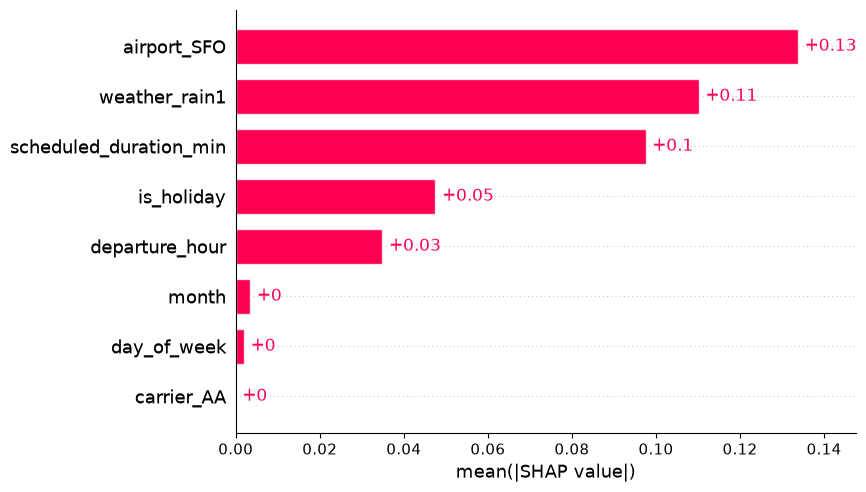

In [ ]:
shap.plots.bar(shap_delayed, max_display=len(selected_feature_names_for_tree))

# Direction and variation across flights

Each dot in the beeswarm plot is a flight.

- Horizontal position shows the signed contribution; color shows the feature value.
- E.g., check the contribution of rain forecasts

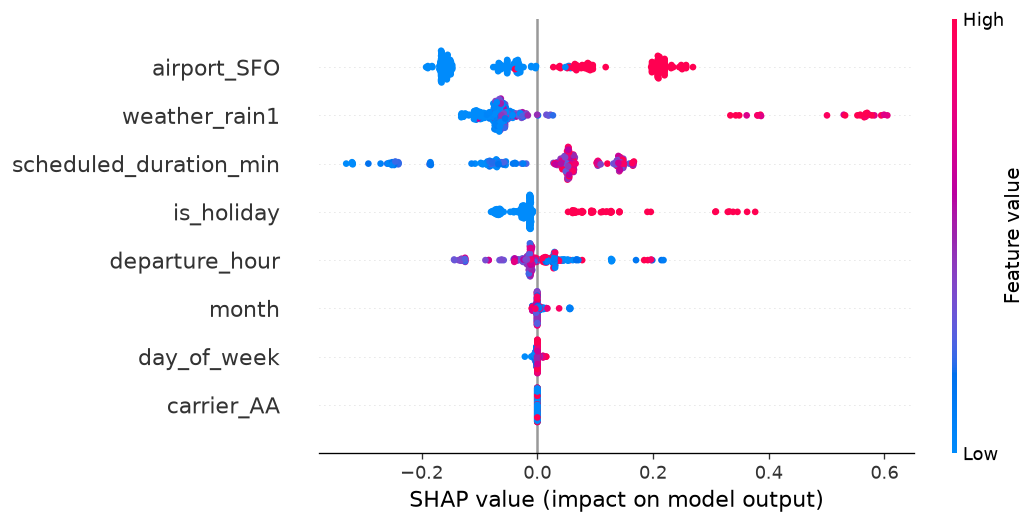

In [ ]:
shap.plots.beeswarm(shap_delayed, max_display=len(selected_feature_names_for_tree))

# Local SHAP contributions: explain one flight

In [346]:
#| echo: false
#| output: false
flight_position = 0  # Change this to inspect another validation flight.
flight_explanation = shap_delayed[flight_position]
flight_explanation
local_contributions = pd.DataFrame({
    "tree_feature": selected_feature_names_for_tree,
    "feature_value": X_explain.iloc[flight_position].to_numpy(),
    "shap_contribution": flight_explanation.values,
})
local_contributions["contribution_percentage_points"] = 100 * local_contributions["shap_contribution"]
local_contributions = local_contributions.iloc[
    np.argsort(-np.abs(local_contributions["shap_contribution"].to_numpy()))
]
local_contributions.round(4)


,tree_feature,feature_value,shap_contribution,contribution_percentage_points
6,is_holiday,0.00,-0.1496,-14.9640
0,distance_km,0.58,-0.0669,-6.6914
5,departure_hour,0.00,-0.0633,-6.3262
1,weather_wind2,303.00,0.0520,5.1966
2,weather_rain1,4.00,0.0291,2.9145
3,weather_rain2,2.00,-0.0026,-0.2606
4,noise_3,3.00,0.0000,0.0000
7,airport_SFO,0.00,0.0000,0.0000


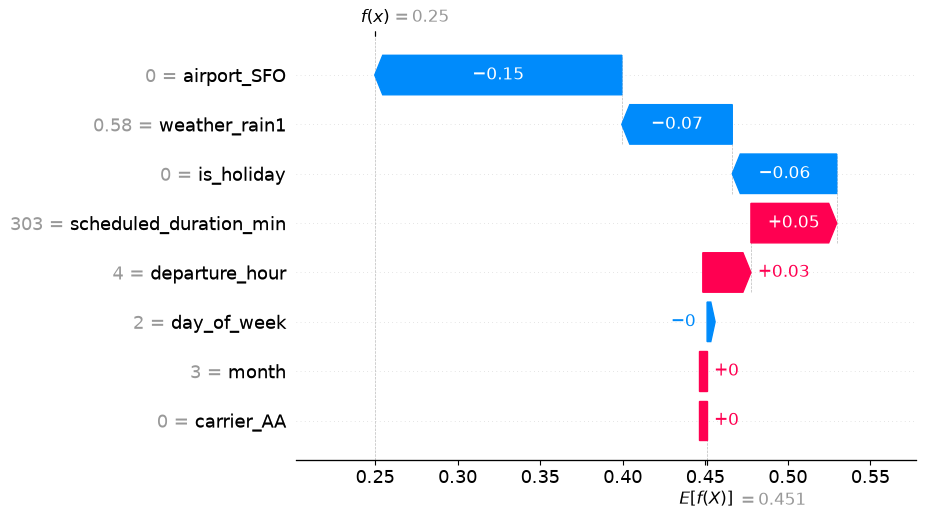

In [347]:
shap.plots.waterfall(flight_explanation, max_display=len(selected_feature_names_for_tree))

Check that the base value plus all signed contributions equals the model's predicted probability.


In [ ]:
#| echo: false
pd.DataFrame([{
    "flight_index": X_explain.index[flight_position],
    "base_probability": float(flight_explanation.base_values),
    "sum_of_contributions": float(flight_explanation.values.sum()),
    "reconstructed_probability": float(flight_explanation.base_values + flight_explanation.values.sum()),
    "predicted_probability": delayed_probability[flight_position],
}])


,flight_index,base_probability,sum_of_contributions,reconstructed_probability,predicted_probability
0,3701,0.451106,-0.20131,0.249797,0.249797


# Permutation importance measures score decrease; SHAP measures probability-contribution magnitude.

In [348]:
#| echo: false
#| output: false
importance_comparison = importance_table.merge(shap_importance, on="tree_feature")
importance_comparison["permutation_rank"] = importance_comparison["importance_mean"].rank(ascending=False, method="min")
importance_comparison["shap_rank"] = importance_comparison["mean_abs_shap"].rank(ascending=False, method="min")
importance_comparison.sort_values("shap_rank").round(4)

,tree_feature,importance_mean,importance_std,mean_abs_shap,mean_signed_shap,permutation_rank,shap_rank
3,is_holiday,0.0379,0.0031,0.1338,-0.0067,4.0,1.0
2,distance_km,0.0656,0.0057,0.1102,-0.0146,3.0,2.0
7,weather_wind2,-0.0010,0.0008,0.0975,0.0181,8.0,3.0
4,departure_hour,0.0254,0.0040,0.0475,0.0010,5.0,4.0
1,weather_rain1,0.1191,0.0045,0.0349,-0.0003,2.0,5.0
6,noise_3,0.0007,0.0006,0.0035,0.0012,7.0,6.0
5,weather_rain2,0.0156,0.0049,0.0020,-0.0008,6.0,7.0
0,airport_SFO,0.1430,0.0108,0.0000,0.0000,1.0,8.0


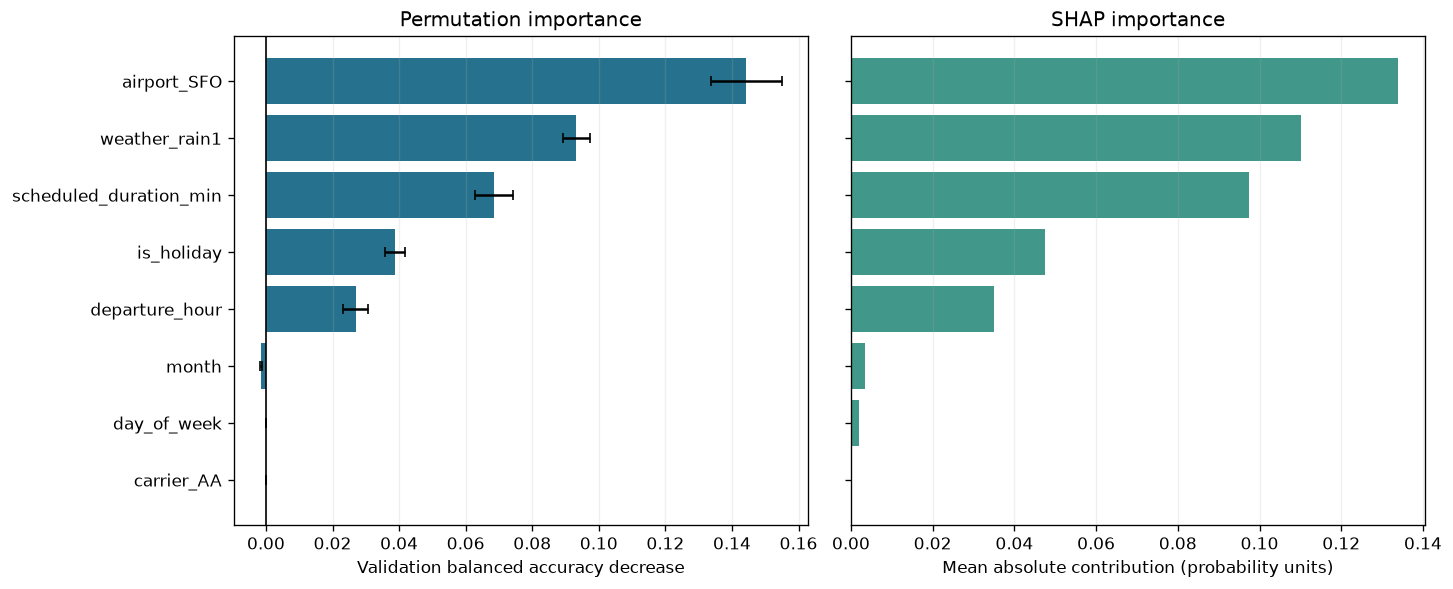

In [ ]:
#| echo: false
#| out-height: "400px"

importance_plot = importance_comparison.sort_values('mean_abs_shap')
positions = np.arange(len(importance_plot))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout='constrained')
axes[0].barh(positions, importance_plot['importance_mean'],
             xerr=importance_plot['importance_std'], capsize=3, color='#26728e')
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set(yticks=positions, yticklabels=importance_plot['tree_feature'],
            xlabel='Validation balanced accuracy decrease', title='Permutation importance')
axes[1].barh(positions, importance_plot['mean_abs_shap'], color='#419789')
axes[1].set(xlabel='Mean absolute contribution (probability units)', title='SHAP importance')
for ax in axes:
    ax.grid(axis='x', alpha=0.2)
plt.show()
